# 최종 모델 성능 확인 (TEST 정확도 · 혼동행렬)
`01_coding/model/`의 최종 가중치로 **TEST 셋을 평가해 정확도와 혼동행렬만** 보여 준다. 학습·튜닝 과정은 `final_model.ipynb`에 있다.

| 셋 | 장수 | 내용 |
|---|---|---|
| test | 2,328 | Kaggle 원본 테스트 (12클래스) — 공개 데이터라 어디서나 실행됨 |
| test_ext | 360 | 외부 실사 사진 (AI Hub 180 + RealWaste 180, 9클래스) — AI Hub 사진이 없으면 저장된 결과로 표시 |

- **로컬**: 저장소의 `01_coding/notebooks/`에서 열고 위에서부터 실행.
- **Colab**: 노트북만 열고 실행하면 GitHub 저장소(모델·사진 목록)와 Google Drive 공개 폴더(이미지 zip)를 내려받는다.
- 이 노트북은 결과를 파일로 저장하지 않는다(보여 주기만). 1회 평가 기록은 `01_coding/RESULT/final_test/`에 있다.

In [1]:
# [셀 목적] 라이브러리, 경로, Colab이면 저장소·이미지 내려받기
import io, json, subprocess, sys, zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from torchvision import transforms   # 이미지 변환만 사용 (사전학습 모델은 쓰지 않음)

IN_COLAB = "google.colab" in sys.modules
REPO = "https://github.com/AnSeokHyeon1212/Garbage_Classification.git"
DRIVE_FOLDER_ID = "19R4yPCNI2B204UuINfGlBx4IZ7N2j9XB"   # 이미지 zip이 있는 Google Drive 공개 폴더
ZIPS = ["kaggle_garbage_classification.zip", "realwaste.zip", "aihub_recycling.zip", "aihub_extra.zip"]   # test·test_ext에 필요한 것만

if IN_COLAB:
    subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-nanum"], check=False, capture_output=True)
    import matplotlib.font_manager as fm
    for f in Path("/usr/share/fonts/truetype/nanum").glob("NanumGothic*.ttf"):
        fm.fontManager.addfont(str(f))
    plt.rcParams["font.family"] = "NanumGothic"
    ROOT = Path("/content/Garbage_Classification")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, str(ROOT)], check=True)
else:
    plt.rcParams["font.family"] = "Malgun Gothic"
    ROOT = Path.cwd().resolve().parents[1]
plt.rcParams["axes.unicode_minus"] = False
CODING = ROOT / "01_coding"
MODEL_DIR = CODING / "model"
DATA_DIR = CODING / "RESULT" / "data_split"
SAVED = CODING / "RESULT" / "final_test"


def fetch_images(root: Path):
    """Colab: Drive 공개 폴더에서 필요한 zip만 받아 root에 푼다 (공개되지 않은 zip은 건너뜀)"""
    import gdown, requests
    tmp = Path("/content/zips")
    for f in gdown.download_folder(id=DRIVE_FOLDER_ID, output=str(tmp), quiet=True, skip_download=True):
        name = Path(f.path).name
        if name not in ZIPS or (root / f".{name}.done").exists():
            continue
        r = requests.get("https://drive.usercontent.google.com/download",
                         params={"id": f.id, "export": "download", "confirm": "t"}, stream=True, timeout=60)
        if r.status_code != 200 or "text/html" in r.headers.get("Content-Type", ""):
            print("내려받지 못함(비공개 등):", name)
            continue
        dst = tmp / name
        dst.parent.mkdir(parents=True, exist_ok=True)
        with open(dst, "wb") as w:
            for chunk in r.iter_content(1 << 20):
                w.write(chunk)
        with zipfile.ZipFile(dst) as z:
            z.extractall(root)
        (root / f".{name}.done").touch()
        dst.unlink()
        print("풀기 완료:", name)


if IN_COLAB:
    fetch_images(ROOT)
print("저장소 루트:", ROOT)

저장소 루트: D:\데이터 분석\빅데이터_프로그래밍


In [2]:
# [셀 목적] 모델 정의(final_model.ipynb 7절과 같은 코드)와 최종 가중치·설정 불러오기
class BasicBlock(nn.Module):
    """3×3 합성곱 2개 + 지름길(identity, 크기·채널이 바뀌면 1×1 합성곱)"""
    def __init__(self, cin: int, cout: int, stride: int):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout)
        self.shortcut = nn.Sequential()
        if stride != 1 or cin != cout:
            self.shortcut = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return torch.relu(out + self.shortcut(x))


class SmallResNet(nn.Module):
    """줄기 → 4단계(채널 w,2w,4w,8w × 블록 2개) → 전역 평균 풀링 → 헤드"""
    def __init__(self, width: int = 32, hidden: tuple = (), num_classes: int = 12):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, width, 3, 2, 1, bias=False), nn.BatchNorm2d(width), nn.ReLU())
        blocks, cin = [], width
        for i, mult in enumerate([1, 2, 4, 8]):
            for j in range(2):
                blocks.append(BasicBlock(cin, width * mult, 2 if (j == 0 and i > 0) else 1))
                cin = width * mult
        self.layers = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        head, d = [], cin
        for h in hidden:
            head += [nn.Linear(d, h), nn.ReLU()]
            d = h
        self.fc = nn.Sequential(*head, nn.Linear(d, num_classes))
        for m in self.modules():  # 합성곱은 He(kaiming) 초기화
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")

    def forward(self, x):
        return self.fc(torch.flatten(self.pool(self.layers(self.stem(x))), 1))


cfg = json.load(open(MODEL_DIR / "config.json", encoding="utf-8"))
CLASSES = cfg["classes"]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SmallResNet(width=cfg["width"], hidden=tuple(cfg["hidden"]))
model.load_state_dict(torch.load(MODEL_DIR / "final_model.pth", map_location="cpu"))
model = model.to(DEVICE).eval()
print(f"최종 모델 {cfg['exp_id']} | 파라미터 {cfg['n_params']:,}개 | 입력 {cfg['img_size']}px | 장치 {DEVICE}")

최종 모델 M8 | 파라미터 6,289,212개 | 입력 128px | 장치 cpu


In [3]:
# [셀 목적] TEST 셋 평가: 학습 때와 같은 전처리(192px로 줄임 → 128px → 정규화)로 예측. 이미지가 없으면 그 셋은 건너뜀
split = pd.read_csv(DATA_DIR / "split.csv")
TEST_SETS = {"test": split[split.split == "test"].reset_index(drop=True),
             "test_ext": pd.read_csv(DATA_DIR / "test_ext_clean.csv")}
tf = transforms.Compose([transforms.Resize((cfg["img_size"], cfg["img_size"])), transforms.ToTensor(),
                         transforms.Normalize(cfg["mean"], cfg["std"])])


@torch.no_grad()
def predict(df: pd.DataFrame, batch: int = 128) -> np.ndarray:
    out = []
    for s in range(0, len(df), batch):
        x = torch.stack([tf(Image.open(ROOT / p).convert("RGB").resize((cfg["cache_size"], cfg["cache_size"]), Image.BILINEAR))
                         for p in df.path.iloc[s:s + batch]])
        out.append(model(x.to(DEVICE)).argmax(1).cpu().numpy())
    return np.concatenate(out)


results = {}
for name, df in TEST_SETS.items():
    have = df.path.map(lambda p: (ROOT / p).exists())
    if not have.all():
        print(f"{name}: 이미지 {int((~have).sum())}장이 없어 저장된 결과로 표시")
        continue
    pred = predict(df)
    true = df.label.map(CLASSES.index).to_numpy()
    results[name] = (true, pred)
    print(f"{name}: 정확도 {(pred == true).mean():.4f} (n={len(df)})")

test: 정확도 0.8823 (n=2328)


test_ext: 정확도 0.9028 (n=360)


,장수,정확도,출처
test,2328,0.8823,지금 평가
test_ext,360,0.9028,지금 평가


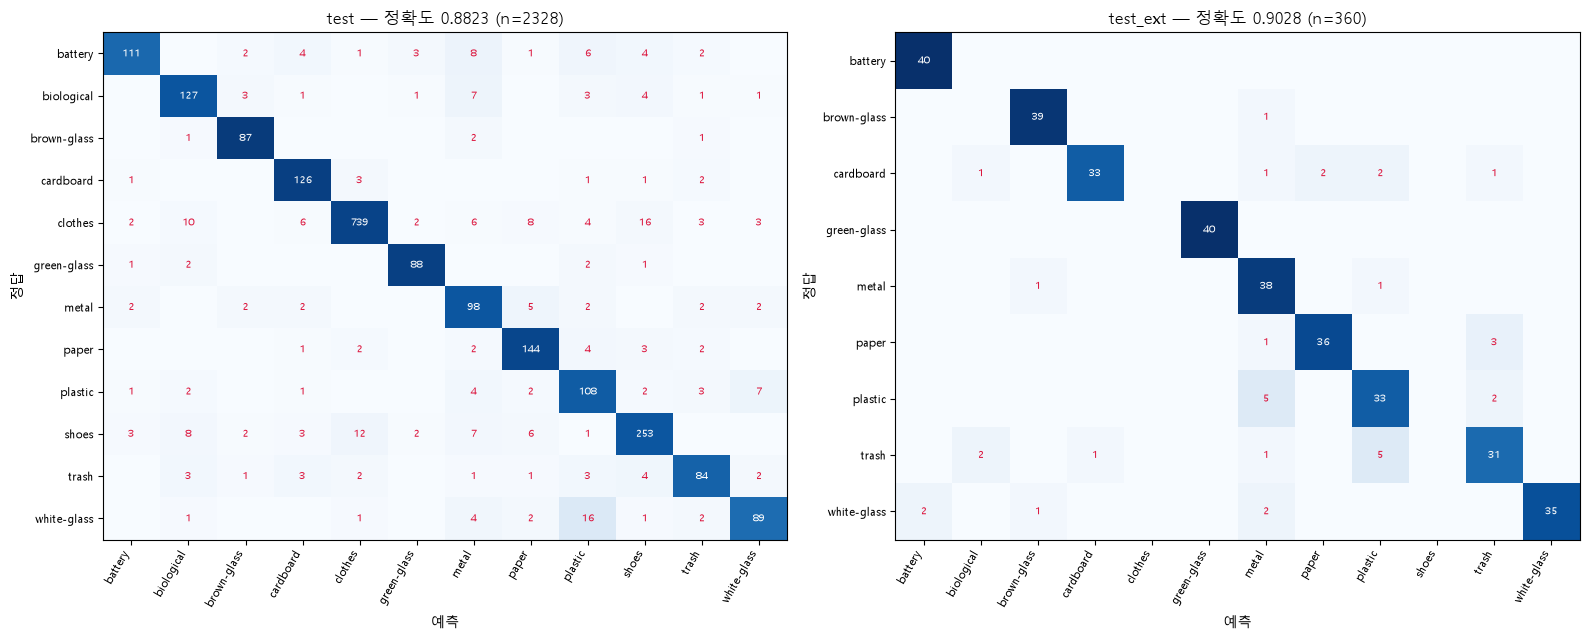

[test] 클래스별 재현율(그 클래스 사진 중 맞힌 비율)·정밀도(그 클래스로 예측한 것 중 맞은 비율)


,장수,재현율,정밀도
정답,,,
battery,142,0.782,0.917
biological,148,0.858,0.825
brown-glass,91,0.956,0.897
cardboard,134,0.940,0.857
clothes,799,0.925,0.972
green-glass,94,0.936,0.917
metal,115,0.852,0.705
paper,158,0.911,0.852
plastic,130,0.831,0.720


[test_ext] 클래스별 재현율(그 클래스 사진 중 맞힌 비율)·정밀도(그 클래스로 예측한 것 중 맞은 비율)


,장수,재현율,정밀도
정답,,,
battery,40,1.000,0.952
brown-glass,40,0.975,0.951
cardboard,40,0.825,0.971
green-glass,40,1.000,1.000
metal,40,0.950,0.776
paper,40,0.900,0.947
plastic,40,0.825,0.805
trash,40,0.775,0.838
white-glass,40,0.875,1.000


In [4]:
# [셀 목적] 정확도 표·혼동행렬·클래스별 정밀도/재현율 (이미지가 없던 셋은 RESULT/final_test/의 저장된 1회 평가 결과)
def confusion(true, pred) -> pd.DataFrame:
    t, p = np.array(CLASSES)[true], np.array(CLASSES)[pred]
    rows = [c for c in CLASSES if c in set(t)]
    return pd.crosstab(pd.Series(t, name="정답"), pd.Series(p, name="예측")).reindex(index=rows, columns=CLASSES, fill_value=0)


cms, source = {}, {}
for name in TEST_SETS:
    if name in results:
        cms[name], source[name] = confusion(*results[name]), "지금 평가"
    else:
        cms[name] = pd.read_csv(SAVED / f"final_{name}_confusion.csv", index_col=0)
        source[name] = "저장된 1회 평가"
acc = {k: np.trace(cm.reindex(columns=cm.index).values) / cm.values.sum() for k, cm in cms.items()}
display(pd.DataFrame({"장수": {k: int(cm.values.sum()) for k, cm in cms.items()},
                      "정확도": {k: round(v, 4) for k, v in acc.items()}, "출처": source}))

fig, axes = plt.subplots(1, len(cms), figsize=(8 * len(cms), 6.5))
for ax, (name, cm) in zip(np.atleast_1d(axes), cms.items()):
    rate = cm.values / np.maximum(cm.values.sum(1, keepdims=True), 1)
    ax.imshow(rate, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if cm.values[i, j]:
                ax.text(j, i, cm.values[i, j], ha="center", va="center", fontsize=7,
                        color="white" if rate[i, j] > 0.5 else ("crimson" if cm.index[i] != cm.columns[j] else "black"))
    ax.set_xticks(range(cm.shape[1]), cm.columns, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(cm.shape[0]), cm.index, fontsize=8)
    ax.set(title=f"{name} — 정확도 {acc[name]:.4f} (n={int(cm.values.sum())})", xlabel="예측", ylabel="정답")
plt.tight_layout()
plt.show()

for name, cm in cms.items():
    tp = np.array([cm.loc[c, c] for c in cm.index])
    rep = pd.DataFrame({"장수": cm.sum(axis=1).values, "재현율": tp / cm.sum(axis=1).values,
                        "정밀도": tp / np.maximum(cm[cm.index].sum(axis=0).values, 1)}, index=cm.index).round(3)
    print(f"[{name}] 클래스별 재현율(그 클래스 사진 중 맞힌 비율)·정밀도(그 클래스로 예측한 것 중 맞은 비율)")
    display(rep)

In [5]:
# [셀 목적] 참고: 더러운 사진 추가 평가(12-2절, 1회 평가 기록) 요약 — 원본/손상, 손상 종류별 정확도
dp = SAVED / "dirty_test_predictions.csv"
if dp.exists():
    d = pd.read_csv(dp)
    print(f"더러운 사진 1,200장 정확도 {d.ok.mean():.4f} | 원본 {d[d.corruption == 'none'].ok.mean():.4f} / 손상 {d[d.corruption != 'none'].ok.mean():.4f}")
    display(d[d.corruption != "none"].pivot_table(index="corruption", columns="severity", values="ok", aggfunc="mean").round(3))

더러운 사진 1,200장 정확도 0.7733 | 원본 0.8264 / 손상 0.7205


severity,mild,strong
corruption,,
blur,0.795,0.649
dark,0.791,0.865
glare,0.614,0.276
jpeg,0.778,0.750
low_light_noise,0.730,0.514
motion_blur,0.784,0.757
noise,0.889,0.649
stain,0.932,0.600
